# Ứng dụng Generative AI trong công việc Data Analyst

**Mục tiêu:** kết hợp Python/pandas với GenAI theo quy trình:

> Data → Python Analysis → GenAI Assistance → Human Verification → Business Decision

Notebook này **không gọi API GenAI**. Sinh viên copy các prompt được cung cấp sang ChatGPT/Gemini/Claude,
sau đó đưa kết quả đã kiểm chứng trở lại notebook/báo cáo.


## Quy tắc sử dụng GenAI trong bài

1. Không tải dữ liệu nhạy cảm hoặc thông tin cá nhân lên công cụ GenAI công cộng.
2. AI có thể sinh code nhưng sinh viên phải chạy và kiểm tra.
3. AI có thể diễn giải nhưng chỉ số liệu do Python tính mới được xem là nguồn kiểm chứng.
4. Không chấp nhận kết luận nếu dữ liệu không hỗ trợ.
5. Lưu Prompt Log.


## 1. Import thư viện


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.2f}".format


## 2. Đọc dữ liệu


In [2]:
df = pd.read_csv("TH02_business_transactions_genai.csv")
df.head()


,TransactionID,Date,CustomerID,Product,Category,Quantity,UnitPrice,UnitCost,Region,Channel,SatisfactionScore,ReviewText
0,T000001,2025-01-12,C00814,Monitor 24,Display,2,3179000,"2,544,000.00",South,Marketplace,4,"Giá hợp lý, trải nghiệm mua hàng tốt."
1,T000002,2025-08-31,C01095,Monitor 27,Display,3,5068000,"4,101,000.00",South,Online,4,"Nhân viên tư vấn nhiệt tình, tôi khá hài lòng."
2,T000003,2025-09-24,C01460,SSD 2TB,Storage,6,4021000,"2,948,000.00",Central,Marketplace,5,"Sản phẩm đáp ứng nhu cầu, sẽ cân nhắc mua lại."
3,T000004,2025-06-05,C01475,Printer,Office Equipment,1,5189000,"4,032,000.00",South,Offline,1,"Giá cao hơn kỳ vọng, trải nghiệm chưa tốt."
4,T000005,2025-02-26,C01760,SSD 1TB,Storage,4,2182000,"1,761,000.00",Central,Marketplace,2,"Giá cao hơn kỳ vọng, trải nghiệm chưa tốt."


### Kiểm tra kích thước, kiểu dữ liệu và missing


In [3]:
print("Shape:", df.shape)
df.info()


Shape: (12080, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12080 entries, 0 to 12079
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      12080 non-null  object 
 1   Date               12080 non-null  object 
 2   CustomerID         12080 non-null  object 
 3   Product            12080 non-null  object 
 4   Category           12080 non-null  object 
 5   Quantity           12080 non-null  int64  
 6   UnitPrice          12080 non-null  int64  
 7   UnitCost           12056 non-null  float64
 8   Region             12032 non-null  object 
 9   Channel            12044 non-null  object 
 10  SatisfactionScore  12080 non-null  int64  
 11  ReviewText         12019 non-null  object 
dtypes: float64(1), int64(3), object(8)
memory usage: 1.1+ MB


In [4]:
df.isna().sum().sort_values(ascending=False)


ReviewText           61
Region               48
Channel              36
UnitCost             24
Product               0
CustomerID            0
Date                  0
TransactionID         0
UnitPrice             0
Quantity              0
Category              0
SatisfactionScore     0
dtype: int64

In [5]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 80


## Hoạt động GenAI P01 – Lập kế hoạch EDA

Mở file **Bo_prompt_mau_GenAI_Data_Analyst.md**, dùng prompt **P01**.

### Nhiệm vụ
- So sánh kế hoạch EDA của AI với các phép kiểm tra ở trên.
- Ghi vào Prompt Log ít nhất 1 điểm AI đề xuất hợp lý và 1 điểm cần kiểm chứng.


## 3. Kiểm tra dữ liệu bất thường


In [6]:
checks = {
    "Quantity <= 0": (df["Quantity"] <= 0).sum(),
    "UnitPrice <= 0": (df["UnitPrice"] <= 0).sum(),
    "UnitCost <= 0": (pd.to_numeric(df["UnitCost"], errors="coerce") <= 0).sum(),
}
checks


{'Quantity <= 0': np.int64(37),
 'UnitPrice <= 0': np.int64(12),
 'UnitCost <= 0': np.int64(0)}

### Thảo luận
Không phải mọi outlier đều là lỗi.  
Ví dụ một đơn hàng có Quantity rất lớn có thể là khách hàng doanh nghiệp.

Hãy dùng **P03** để hỏi AI về checklist làm sạch, sau đó đánh dấu:
- ✓ hợp lý
- ? cần kiểm chứng
- ✗ không phù hợp


## 4. Làm sạch cơ bản


In [7]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Bỏ duplicate hoàn toàn
df = df.drop_duplicates().copy()

# Điền missing cho biến phân loại
df["Region"] = df["Region"].fillna("Unknown")
df["Channel"] = df["Channel"].fillna("Unknown")

# UnitCost: điền median theo Product
df["UnitCost"] = (
    df.groupby("Product")["UnitCost"]
      .transform(lambda s: s.fillna(s.median()))
)

df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   TransactionID      12000 non-null  object        
 1   Date               12000 non-null  datetime64[ns]
 2   CustomerID         12000 non-null  object        
 3   Product            12000 non-null  object        
 4   Category           12000 non-null  object        
 5   Quantity           12000 non-null  int64         
 6   UnitPrice          12000 non-null  int64         
 7   UnitCost           12000 non-null  float64       
 8   Region             12000 non-null  object        
 9   Channel            12000 non-null  object        
 10  SatisfactionScore  12000 non-null  int64         
 11  ReviewText         11940 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(3), object(7)
memory usage: 1.2+ MB


> Lưu ý: xử lý `Quantity <= 0` và `UnitPrice <= 0` cần quyết định nghiệp vụ.
> Trong notebook này ta tạo một DataFrame sạch dùng cho KPI bằng cách chỉ giữ giao dịch có số lượng và giá bán dương.


In [8]:
df_clean = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["UnitCost"] > 0)
].copy()

print("Rows after business-rule filtering:", len(df_clean))


Rows after business-rule filtering: 11951


## 5. Tạo KPI: kiểm chứng code do AI sinh


In [9]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]
df_clean["Cost"] = df_clean["Quantity"] * df_clean["UnitCost"]
df_clean["Profit"] = df_clean["Revenue"] - df_clean["Cost"]
df_clean["ProfitMargin"] = np.where(
    df_clean["Revenue"] != 0,
    df_clean["Profit"] / df_clean["Revenue"],
    np.nan
)

df_clean[["Revenue","Cost","Profit","ProfitMargin"]].describe()


,Revenue,Cost,Profit,ProfitMargin
count,"11,951.00","11,951.00","11,951.00","11,951.00"
mean,"22,663,193.54","17,702,977.07","4,960,216.47",0.24
std,"35,365,558.46","28,360,131.42","7,491,957.50",0.06
min,"1,664,000.00","1,182,000.00","-1,384,000.00",-0.05
25%,"5,824,500.00","4,260,500.00","1,400,000.00",0.20
50%,"12,516,000.00","9,582,000.00","2,808,000.00",0.24
75%,"25,416,000.00","19,908,500.00","5,700,000.00",0.28
max,"1,205,631,000.00","1,001,952,000.00","203,679,000.00",0.43


### Hoạt động GenAI P02
Dùng prompt **P02** và so sánh code AI sinh với code ở trên.

Trả lời:
1. Code có xử lý chia cho 0 không?
2. Có làm mất missing value không?
3. Có thêm giả định nghiệp vụ nào không?


## 6. KPI tổng quan


In [10]:
kpis = {
    "Total Revenue": df_clean["Revenue"].sum(),
    "Total Profit": df_clean["Profit"].sum(),
    "Transactions": df_clean["TransactionID"].nunique(),
    "Customers": df_clean["CustomerID"].nunique(),
    "Overall Profit Margin": df_clean["Profit"].sum() / df_clean["Revenue"].sum()
}
kpis


{'Total Revenue': np.int64(270847826000),
 'Total Profit': np.float64(59279547000.0),
 'Transactions': 11951,
 'Customers': 2189,
 'Overall Profit Margin': np.float64(0.21886661552897235)}

## 7. Phân tích theo Region


In [11]:
region_summary = (
    df_clean.groupby("Region")
    .agg(
        Revenue=("Revenue","sum"),
        Profit=("Profit","sum"),
        Transactions=("TransactionID","nunique"),
        Customers=("CustomerID","nunique")
    )
)
region_summary["ProfitMargin"] = region_summary["Profit"] / region_summary["Revenue"]
region_summary.sort_values("Revenue", ascending=False)


,Revenue,Profit,Transactions,Customers,ProfitMargin
Region,,,,,
South,141278709000,"30,908,657,500.00",6232,2080,0.22
North,72868927000,"15,896,844,500.00",3236,1675,0.22
Central,55970784000,"12,310,788,000.00",2436,1471,0.22
Unknown,729406000,"163,257,000.00",47,46,0.22


### Hoạt động GenAI P05: Diễn giải insight
Copy bảng `region_summary` sang AI bằng prompt **P05**.

Đối với mỗi insight AI tạo ra, gắn nhãn:
- `[SUPPORTED]`
- `[NEEDS CHECK]`
- `[UNSUPPORTED]`


## 8. Phân tích theo Channel


In [12]:
channel_summary = (
    df_clean.groupby("Channel")
    .agg(
        Revenue=("Revenue","sum"),
        Profit=("Profit","sum"),
        Transactions=("TransactionID","nunique")
    )
)
channel_summary["ProfitMargin"] = channel_summary["Profit"] / channel_summary["Revenue"]
channel_summary


,Revenue,Profit,Transactions,ProfitMargin
Channel,,,,
Marketplace,53307338000,"11,825,596,000.00",2462,0.22
Offline,86221027000,"18,714,273,500.00",3789,0.22
Online,130365230000,"28,532,397,500.00",5664,0.22
Unknown,954231000,"207,280,000.00",36,0.22


## 9. Trực quan hóa: kiểm chứng đề xuất của AI


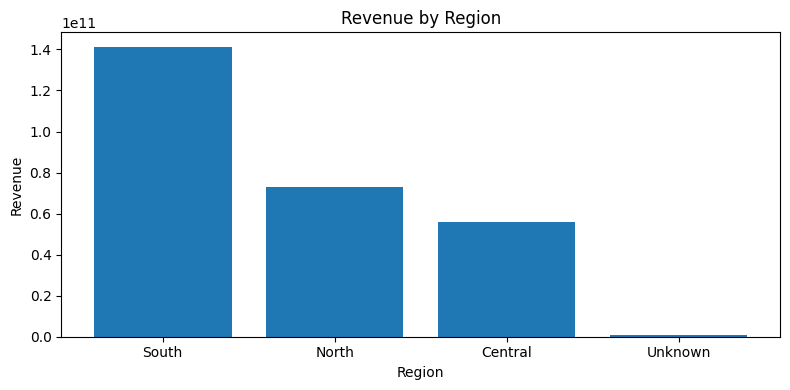

In [13]:
plot_df = region_summary.sort_values("Revenue", ascending=False)

fig, ax = plt.subplots(figsize=(8,4))
ax.bar(plot_df.index, plot_df["Revenue"])
ax.set_title("Revenue by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Revenue")
plt.tight_layout()
plt.show()


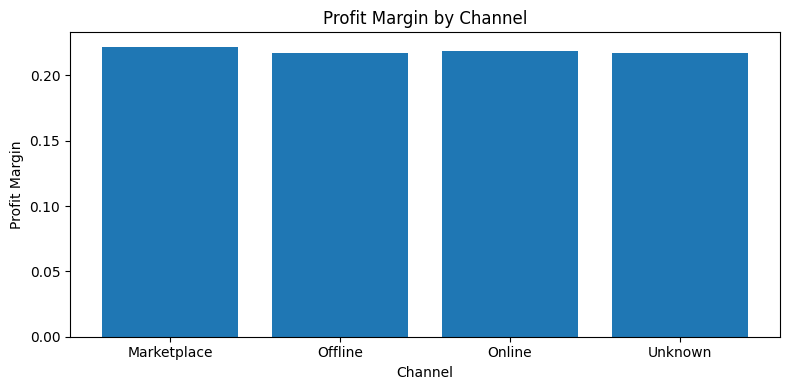

In [14]:
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(channel_summary.index, channel_summary["ProfitMargin"])
ax.set_title("Profit Margin by Channel")
ax.set_xlabel("Channel")
ax.set_ylabel("Profit Margin")
plt.tight_layout()
plt.show()


### Hoạt động GenAI P06
Dùng prompt **P06** để AI đề xuất biểu đồ.
Sau đó:
1. chạy code AI sinh;
2. so sánh với biểu đồ trong notebook;
3. nhận xét chart nào dễ hiểu hơn và vì sao.


## 10. Phân tích khách hàng – Pareto


In [15]:
customer = (
    df_clean.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

customer["CumRevenue"] = customer["Revenue"].cumsum()
customer["CumPct"] = customer["CumRevenue"] / customer["Revenue"].sum()

share_customers_80 = (customer["CumPct"] <= 0.80).mean()
print(f"Tỷ lệ khách hàng tạo ra gần 80% doanh thu: {share_customers_80:.2%}")
customer.head(10)


Tỷ lệ khách hàng tạo ra gần 80% doanh thu: 54.00%


,CustomerID,Revenue,CumRevenue,CumPct
0,C00679,1276606000,1276606000,0.00
1,C02074,1006491000,2283097000,0.01
2,C00985,1004103000,3287200000,0.01
3,C00548,903023000,4190223000,0.02
4,C00080,812870000,5003093000,0.02
5,C01248,641351000,5644444000,0.02
6,C02016,613672000,6258116000,0.02
7,C00057,562000000,6820116000,0.03
8,C00263,552226000,7372342000,0.03
9,C00634,551334000,7923676000,0.03


## 11. Dữ liệu phi cấu trúc: ReviewText

GenAI đặc biệt hữu ích khi dữ liệu là văn bản.
Ta lấy một mẫu review để sinh viên dùng prompt **P07**.


In [16]:
sample_reviews = (
    df_clean["ReviewText"]
    .dropna()
    .sample(30, random_state=42)
    .tolist()
)

for i, review in enumerate(sample_reviews, 1):
    print(f"{i:02d}. {review}")


01. Giao hàng nhanh, sản phẩm tốt và đúng mô tả.
02. Nhân viên tư vấn nhiệt tình, tôi khá hài lòng.
03. Chất lượng ổn định, đóng gói cẩn thận.
04. Giá hợp lý, trải nghiệm mua hàng tốt.
05. Nhân viên tư vấn nhiệt tình, tôi khá hài lòng.
06. Giao hàng chậm, hộp bị móp khi nhận.
07. Chất lượng ổn định, đóng gói cẩn thận.
08. Chất lượng ổn định, đóng gói cẩn thận.
09. Giao hàng nhanh, sản phẩm tốt và đúng mô tả.
10. Sản phẩm đúng mô tả, chưa sử dụng lâu.
11. Giá hợp lý, trải nghiệm mua hàng tốt.
12. Nhân viên tư vấn nhiệt tình, tôi khá hài lòng.
13. Giá hợp lý, trải nghiệm mua hàng tốt.
14. Chất lượng ổn định, đóng gói cẩn thận.
15. Giao hàng nhanh, sản phẩm tốt và đúng mô tả.
16. Nhân viên tư vấn nhiệt tình, tôi khá hài lòng.
17. Sản phẩm đúng mô tả, chưa sử dụng lâu.
18. Chất lượng ổn định, đóng gói cẩn thận.
19. Chất lượng ổn định, đóng gói cẩn thận.
20. Chất lượng ổn định, đóng gói cẩn thận.
21. Chất lượng ổn định, đóng gói cẩn thận.
22. Nhân viên tư vấn nhiệt tình, tôi khá hài lòng.
2

### Hoạt động GenAI P07
Copy 20-30 review trên vào AI.

Yêu cầu:
- nhóm tối đa 5 chủ đề;
- sentiment;
- ví dụ đại diện;
- **không được suy tỷ lệ toàn dataset từ mẫu**.

Sau đó kiểm tra xem AI có vi phạm điều kiện cuối không.


## 12. Kiểm tra sentiment bằng dữ liệu có cấu trúc


In [17]:
score_summary = (
    df_clean.groupby("SatisfactionScore")
    .size()
    .rename("Count")
    .to_frame()
)
score_summary["Pct"] = score_summary["Count"] / score_summary["Count"].sum()
score_summary


,Count,Pct
SatisfactionScore,,
1,574,0.05
2,1015,0.08
3,2343,0.20
4,4553,0.38
5,3466,0.29


So sánh kết quả AI phân tích ReviewText với `SatisfactionScore`.
Hai nguồn có nhất quán không? Nếu không, cần giải thích là đây chỉ là mẫu review chứ không phải toàn bộ dữ liệu.


## 13. Debug với GenAI


In [18]:
# Ví dụ đúng
df_clean.groupby("Region")["Revenue"].mean()


Region
Central   22,976,512.32
North     22,518,209.83
South     22,669,882.70
Unknown   15,519,276.60
Name: Revenue, dtype: float64

### Bài debug
Cố ý sửa dòng trên thành:

```python
df_clean.groupby("Region")["Revenue"].mean
```

Quan sát kết quả và dùng **P04** để yêu cầu AI giải thích vì sao thiếu `()` là vấn đề.


## 14. Hallucination Test


Giả sử chỉ cung cấp cho AI bảng gồm `Region`, `Revenue`, `Profit`.

Dùng prompt **P11**:

> “Khu vực nào có tỷ lệ khách hàng quay lại cao nhất?”

Câu trả lời đúng phải là **không đủ dữ liệu** vì thiếu CustomerID/lịch sử mua lặp lại.

Ghi lại phản hồi của AI vào Prompt Log.


## 15. Executive Summary


In [19]:
verified_summary = {
    "TotalRevenue": df_clean["Revenue"].sum(),
    "TotalProfit": df_clean["Profit"].sum(),
    "BestRegionByRevenue": region_summary["Revenue"].idxmax(),
    "BestChannelByMargin": channel_summary["ProfitMargin"].idxmax(),
}
verified_summary


{'TotalRevenue': np.int64(270847826000),
 'TotalProfit': np.float64(59279547000.0),
 'BestRegionByRevenue': 'South',
 'BestChannelByMargin': 'Marketplace'}

Dùng **P08** và chỉ đưa các KPI đã kiểm chứng ở trên.

Sau khi AI viết Executive Summary:
- tô/đánh dấu mọi con số;
- đối chiếu lại với notebook;
- xóa hoặc sửa mọi nguyên nhân mà dữ liệu chưa chứng minh.


## 16. Công việc văn phòng với GenAI


Chọn **một** trong các prompt:
- P09: Email báo cáo
- P10: Outline 5 slide

Yêu cầu: nội dung phải dựa trên kết quả đã kiểm chứng trong notebook.


## 17. Prompt Self-check


Dùng **P13** để AI tự kiểm tra chính câu trả lời của nó.

So sánh:
- AI tự phát hiện được bao nhiêu vấn đề?
- Có vấn đề nào sinh viên phát hiện nhưng AI không phát hiện?


## 18. Prompt Log: sinh viên điền


| ID | Prompt | AI trả lời tóm tắt | Vấn đề phát hiện | Prompt cải tiến | Cách kiểm chứng |
|---|---|---|---|---|---|
| P01 |  |  |  |  |  |
| P02 |  |  |  |  |  |
| P05 |  |  |  |  |  |
| P11 |  |  |  |  |  |


## 19. Kết luận cuối bài


Viết 150–250 từ trả lời:

1. GenAI giúp Data Analyst tiết kiệm thời gian ở bước nào?
2. Bước nào vẫn bắt buộc con người kiểm chứng?
3. Ví dụ hallucination hoặc suy diễn mà nhóm phát hiện.
4. Một nguyên tắc sử dụng GenAI mà nhóm cho là quan trọng nhất.


## 20. Checklist nộp bài


- [ ] Notebook chạy từ đầu đến cuối
- [ ] Có ít nhất 4 prompt trong Prompt Log
- [ ] Có 1 ví dụ debug bằng GenAI
- [ ] Có 1 hallucination test
- [ ] Có ít nhất 2 biểu đồ
- [ ] Có phân tích ReviewText
- [ ] Có Executive Summary
- [ ] Có kết luận về giới hạn của GenAI
